<a href="https://colab.research.google.com/github/dunurejoice20/electricity-forecasting./blob/Dami-Trial/notebooks/Jay's_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [94]:
import pandas as pd

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values="?"
)

df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [96]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


In [97]:
df.duplicated().sum()

np.int64(0)

In [98]:
df.dtypes

,0
Date,object
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [99]:
df['Date'] = pd.to_datetime(df['Date'],dayfirst=True)

In [100]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [101]:
df['Time'] = pd.to_datetime(df["Time"], format='%H:%M:%S').dt.time

In [102]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [103]:
df['Datetime'] = pd.to_datetime(
    df['Date'].dt.strftime('%Y-%m-%d') +  '' + df['Time'].astype(str),
    errors='coerce'
  )

/tmp/ipykernel_1191/634023205.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Datetime'] = pd.to_datetime(


In [104]:
df[['Date', 'Time', 'Datetime']].head()

,Date,Time,Datetime
0,2006-12-16,17:24:00,NaT
1,2006-12-16,17:25:00,NaT
2,2006-12-16,17:26:00,NaT
3,2006-12-16,17:27:00,NaT
4,2006-12-16,17:28:00,NaT


In [105]:
df['Hour'] = pd.to_datetime(
    df['Time'],
    format='%H:%M:%S'
).dt.hour

In [106]:
df[['Time', 'Hour', ]].head()

,Time,Hour
0,17:24:00,17
1,17:25:00,17
2,17:26:00,17
3,17:27:00,17
4,17:28:00,17


In [107]:
df['Day'] = df['Date'].dt.day

In [108]:
df[['Date', 'Day']].head()

,Date,Day
0,2006-12-16,16
1,2006-12-16,16
2,2006-12-16,16
3,2006-12-16,16
4,2006-12-16,16


In [109]:
df['Month'] = df['Date'].dt.month

In [110]:
df[['Date', 'Month']].head()

,Date,Month
0,2006-12-16,12
1,2006-12-16,12
2,2006-12-16,12
3,2006-12-16,12
4,2006-12-16,12


In [111]:
df['Day_of_week'] = df['Date'].dt.dayofweek

In [112]:
df[['Date', 'Day_of_week']].head()

,Date,Day_of_week
0,2006-12-16,5
1,2006-12-16,5
2,2006-12-16,5
3,2006-12-16,5
4,2006-12-16,5


In [113]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Datetime,2075259


In [114]:
df['Month'] = df['Date'].dt.month

In [115]:
df[['Date', 'Month']].head()

,Date,Month
0,2006-12-16,12
1,2006-12-16,12
2,2006-12-16,12
3,2006-12-16,12
4,2006-12-16,12


In [116]:
df['DayOfWeek'] = df['Date'].dt.dayofweek

In [117]:
df[['Date', 'DayOfWeek']].head()

,Date,DayOfWeek
0,2006-12-16,5
1,2006-12-16,5
2,2006-12-16,5
3,2006-12-16,5
4,2006-12-16,5


In [118]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Datetime,2075259


In [119]:
df.columns.tolist()

['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'Datetime',
 'Hour',
 'Day',
 'Month',
 'Day_of_week',
 'DayOfWeek']

In [120]:
print(df.columns.tolist())

['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime', 'Hour', 'Day', 'Month', 'Day_of_week', 'DayOfWeek']


In [121]:
print(len(df.columns))

15


In [122]:
df.shape

(2075259, 15)

In [123]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Hour,Day,Month,Day_of_week,DayOfWeek
0,2006-12-16,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,NaT,17,16,12,5,5
1,2006-12-16,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,NaT,17,16,12,5,5
2,2006-12-16,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,NaT,17,16,12,5,5
3,2006-12-16,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,NaT,17,16,12,5,5
4,2006-12-16,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,NaT,17,16,12,5,5


In [124]:
df.columns[df.columns.duplicated()]

Index([], dtype='object')

In [125]:
print(df[['Date', 'Hour', 'Month', 'DayOfWeek']].head(10))

        Date  Hour  Month  DayOfWeek
0 2006-12-16    17     12          5
1 2006-12-16    17     12          5
2 2006-12-16    17     12          5
3 2006-12-16    17     12          5
4 2006-12-16    17     12          5
5 2006-12-16    17     12          5
6 2006-12-16    17     12          5
7 2006-12-16    17     12          5
8 2006-12-16    17     12          5
9 2006-12-16    17     12          5


In [126]:
print(df.columns.tolist())

['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime', 'Hour', 'Day', 'Month', 'Day_of_week', 'DayOfWeek']


In [127]:
df.columns[df.columns.duplicated()]

Index([], dtype='object')

In [128]:
for i, col in enumerate(df.columns):
  print(i, repr(col))

0 'Date'
1 'Time'
2 'Global_active_power'
3 'Global_reactive_power'
4 'Voltage'
5 'Global_intensity'
6 'Sub_metering_1'
7 'Sub_metering_2'
8 'Sub_metering_3'
9 'Datetime'
10 'Hour'
11 'Day'
12 'Month'
13 'Day_of_week'
14 'DayOfWeek'


In [129]:
df[['Day_of_week', 'DayOfWeek']].head()

,Day_of_week,DayOfWeek
0,5,5
1,5,5
2,5,5
3,5,5
4,5,5


In [130]:
df = df.drop(columns=['DayOfWeek'])

In [131]:
df.columns.tolist()

['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'Datetime',
 'Hour',
 'Day',
 'Month',
 'Day_of_week']

In [132]:
df.duplicated().sum()

np.int64(0)

In [133]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Datetime,2075259


In [134]:
df.shape

(2075259, 14)

In [135]:
df.isnull().mean() * 100

,0
Date,0.000000
Time,0.000000
Global_active_power,1.251844
Global_reactive_power,1.251844
Voltage,1.251844
Global_intensity,1.251844
Sub_metering_1,1.251844
Sub_metering_2,1.251844
Sub_metering_3,1.251844
Datetime,100.000000


In [136]:
df = df.drop(columns=['Datetime'])

In [137]:
df.shape

(2075259, 13)

In [138]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64
Hour,int32


In [139]:
df['Time'].head()

,Time
0,17:24:00
1,17:25:00
2,17:26:00
3,17:27:00
4,17:28:00


In [140]:
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.time

In [141]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64
Hour,int32


In [142]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979
Hour,0


In [143]:
df[df['Global_active_power'].isnull()].head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day,Month,Day_of_week
6839,2006-12-21,11:23:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,21,12,3
6840,2006-12-21,11:24:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11,21,12,3
19724,2006-12-30,10:08:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,30,12,5
19725,2006-12-30,10:09:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,30,12,5
41832,2007-01-14,18:36:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18,14,1,6


In [144]:
measurement_cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
]

df[measurement_cols].isnull().all(axis=1).sum()

np.int64(25979)

In [145]:
df = df.dropna(subset=measurement_cols)

In [146]:
df.shape

(2049280, 13)

In [147]:
df.isnull().sum()

,0
Date,0
Time,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0
Hour,0


In [148]:
df.duplicated().sum()

np.int64(0)

In [149]:
df.dtypes

,0
Date,datetime64[ns]
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64
Hour,int32


In [150]:
df.describe()

,Date,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day,Month,Day_of_week
count,2049280,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,2008-12-01 13:00:00.309181952,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00,1.150391e+01,1.571245e+01,6.454433e+00,2.989276e+00
min,2006-12-16 00:00:00,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
25%,2007-12-10 00:00:00,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00,8.000000e+00,3.000000e+00,1.000000e+00
50%,2008-11-30 00:00:00,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.200000e+01,1.600000e+01,6.000000e+00,3.000000e+00
75%,2009-11-23 00:00:00,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01,1.800000e+01,2.300000e+01,9.000000e+00,5.000000e+00
max,2010-11-26 00:00:00,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01,2.300000e+01,3.100000e+01,1.200000e+01,6.000000e+00
std,NaN,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00,6.925189e+00,8.801670e+00,3.423209e+00,1.997633e+00


In [151]:
df[['Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',]].min()

,0
Global_active_power,0.076
Global_reactive_power,0.000
Voltage,223.200
Global_intensity,0.200
Sub_metering_1,0.000
Sub_metering_2,0.000
Sub_metering_3,0.000


In [152]:
df[['Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3']].max()

,0
Global_active_power,11.122
Global_reactive_power,1.390
Voltage,254.150
Global_intensity,48.400
Sub_metering_1,88.000
Sub_metering_2,80.000
Sub_metering_3,31.000


In [153]:
df['Date'].min(), df['Date'].max()

(Timestamp('2006-12-16 00:00:00'), Timestamp('2010-11-26 00:00:00'))

In [154]:
df['Date'].is_monotonic_increasing

True

In [155]:
print("Hours below 0:", (df['Hour'] < 0).sum())
print("Hours above 23:", (df['Hour'] > 23).sum())

Hours below 0: 0
Hours above 23: 0


In [156]:
print("Days below 1:", (df['Day'] < 1).sum())
print("Days above 31:", (df['Day'] > 31).sum())

Days below 1: 0
Days above 31: 0


In [157]:
print("Months below 1:", (df['Month'] < 1).sum())
print("Months above 12:", (df['Month'] > 12).sum())

Months below 1: 0
Months above 12: 0


In [158]:
print("Days_of_week below 0:", (df['Day_of_week'] < 0).sum())
print("Days_of_week above 6:", (df['Day_of_week'] > 6).sum())

Days_of_week below 0: 0
Days_of_week above 6: 0


In [159]:
cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3',
]

df[cols].lt(0).sum()

,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [160]:
df.shape

(2049280, 13)

In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2049280 entries, 0 to 2075258
Data columns (total 13 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   datetime64[ns]
 1   Time                   object        
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   Hour                   int32         
 10  Day                    int32         
 11  Month                  int32         
 12  Day_of_week            int32         
dtypes: datetime64[ns](1), float64(7), int32(4), object(1)
memory usage: 187.6+ MB


In [162]:
df["datetime"] = df["Date"] + pd.to_timedelta(df["Time"].astype(str))
df = df.set_index("datetime").sort_index()

hourly = df["Global_active_power"].resample("h").mean()
print("Missing hours:", hourly.isna().sum())

hourly = hourly.interpolate(limit=6)   # fills short gaps only
print("Still missing:", hourly.isna().sum())

hourly.to_frame().reset_index().to_csv("clean_hourly.csv", index=False)

Missing hours: 421
Still missing: 378


Dami & Jay's work Below

In [163]:
#importing needed libraries

import pandas as pd
import numpy as np
import sklearn
import tensorflow as tf

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("TensorFlow version:", tf.__version__)

Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1
TensorFlow version: 2.21.0


In [164]:
import pandas as pd



print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (2049280, 13)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Day,Month,Day_of_week
datetime,,,,,,,,,,,,,
2006-12-16 17:24:00,2006-12-16,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,16,12,5
2006-12-16 17:25:00,2006-12-16,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,16,12,5
2006-12-16 17:26:00,2006-12-16,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,16,12,5
2006-12-16 17:27:00,2006-12-16,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,16,12,5
2006-12-16 17:28:00,2006-12-16,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,16,12,5


In [165]:
features_df = hourly.to_frame(name='Global_active_power')


features_df['hour'] = features_df.index.hour
features_df['day_of_week'] = features_df.index.dayofweek
features_df['month'] = features_df.index.month


features_df['lag_1h'] = features_df['Global_active_power'].shift(1)
features_df['lag_24h'] = features_df['Global_active_power'].shift(24)



features_df['rolling_mean_24h'] = features_df['Global_active_power'].shift(1).rolling(window=24).mean()

# Checking first 30 rows
display(features_df.head(30))

,Global_active_power,hour,day_of_week,month,lag_1h,lag_24h,rolling_mean_24h
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,17,5,12,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,18,5,12,4.222889,NaN,NaN
2006-12-16 19:00:00,3.400233,19,5,12,3.632200,NaN,NaN
2006-12-16 20:00:00,3.268567,20,5,12,3.400233,NaN,NaN
2006-12-16 21:00:00,3.056467,21,5,12,3.268567,NaN,NaN
2006-12-16 22:00:00,2.200133,22,5,12,3.056467,NaN,NaN
2006-12-16 23:00:00,2.061600,23,5,12,2.200133,NaN,NaN
2006-12-17 00:00:00,1.882467,0,6,12,2.061600,NaN,NaN
2006-12-17 01:00:00,3.349400,1,6,12,1.882467,NaN,NaN


In [166]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
import numpy as np

# Drop any rows containing NaN values introduced by shift/lag operations
clean_features = features_df.dropna()

# Define the target variable and the predictor features
target_col = 'Global_active_power'
feature_cols = ['hour', 'day_of_week', 'month', 'lag_1h', 'lag_24h', 'rolling_mean_24h']

X = clean_features[feature_cols]
y = clean_features[target_col]

# Perform a time-based split: the first 80% for training, remaining 20% for testing
split_idx = int(len(clean_features) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (27215, 6)
Testing set shape: (6804, 6)


In [167]:
# Initialize the StandardScaler and fit it on the training set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 1. Linear Regression Baseline ---
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

# --- 2. Random Forest Regressor ---
rf_model = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
rf_preds = rf_model.predict(X_test_scaled)

# --- 3. Keras Neural Network ---
tf.random.set_seed(42)
keras_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

keras_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
keras_model.fit(X_train_scaled, y_train, epochs=15, batch_size=64, validation_split=0.1, verbose=1)
keras_preds = keras_model.predict(X_test_scaled).flatten()

Epoch 1/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4941 - mae: 0.4875 - val_loss: 0.4157 - val_mae: 0.4685
Epoch 2/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3732 - mae: 0.4237 - val_loss: 0.4040 - val_mae: 0.4582
Epoch 3/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3653 - mae: 0.4184 - val_loss: 0.3987 - val_mae: 0.4539
Epoch 4/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3612 - mae: 0.4157 - val_loss: 0.3970 - val_mae: 0.4518
Epoch 5/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3585 - mae: 0.4140 - val_loss: 0.3939 - val_mae: 0.4487
Epoch 6/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3557 - mae: 0.4122 - val_loss: 0.3903 - val_mae: 0.4462
Epoch 7/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3530 - mae: 0.4102 - val_loss: 0.3876 - val_mae: 0.4434
Epoch 8/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3502 - mae: 0.4084 - val_loss: 0.3835 - val_mae: 0.4410
Epoch 9/15
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - lo

In [168]:
# Calculate evaluation metrics (MSE and MAE) for all models
models_metrics = {
    'Linear Regression': {
        'MSE': mean_squared_error(y_test, lr_preds),
        'MAE': mean_absolute_error(y_test, lr_preds)
    },
    'Random Forest': {
        'MSE': mean_squared_error(y_test, rf_preds),
        'MAE': mean_absolute_error(y_test, rf_preds)
    },
    'Keras Neural Network': {
        'MSE': mean_squared_error(y_test, keras_preds),
        'MAE': mean_absolute_error(y_test, keras_preds)
    }
}

metrics_df = pd.DataFrame(models_metrics).T
display(metrics_df)

,MSE,MAE
Linear Regression,0.281882,0.379757
Random Forest,0.234987,0.334952
Keras Neural Network,0.248823,0.358286


In [169]:
import numpy as np
import pandas as pd
import joblib
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Define a helper function to calculate MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    # Prevent division by zero by filtering out actual zeros or adding a small epsilon
    #converts our targets and predictions into Np arrays
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    #creates a boolean filter that removes values equal to 0
    non_zero_mask = y_true != 0
    return np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100


# Dictionary of predictions
predictions = {
    'Linear Regression': lr_preds,
    'Random Forest': rf_preds,
    'Keras Neural Network': keras_preds
}

# Compute MAE, RMSE, and MAPE
comparison_data = {}
for model_name, preds in predictions.items():
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mape = mean_absolute_percentage_error(y_test, preds)

    comparison_data[model_name] = {
        'MAE': mae,
        'RMSE': rmse,
        'MAPE (%)': mape
    }

# Create a DataFrame to display the comparisons
comparison_df = pd.DataFrame(comparison_data).T
display(comparison_df)

# Identify the best model based on RMSE
best_model_name = comparison_df['RMSE'].idxmin()
print(f"\nBest Model based on RMSE: {best_model_name}")

# Save the best model (Random Forest)
if best_model_name == 'Random Forest':
    joblib.dump(rf_model, 'best_random_forest_model.pkl')
    print("Saved Random Forest model as 'best_random_forest_model.pkl'")
elif best_model_name == 'Linear Regression':
    joblib.dump(lr_model, 'best_linear_regression_model.pkl')
    print("Saved Linear Regression model as 'best_linear_regression_model.pkl'")
else:
    keras_model.save('best_keras_model.keras')
    print("Saved Keras Neural Network model as 'best_keras_model.keras'")

,MAE,RMSE,MAPE (%)
Linear Regression,0.379757,0.530926,50.854935
Random Forest,0.334952,0.484755,43.419582
Keras Neural Network,0.358286,0.498822,48.736989



Best Model based on RMSE: Random Forest
Saved Random Forest model as 'best_random_forest_model.pkl'


In [170]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=comparison_df)

https://docs.google.com/spreadsheets/d/12ByuQ11I82VCihojNZmVhy2v5P3xOIGXGJI0iPAiClA/edit#gid=0


Anomaly detection

anomaly_status
Normal     33678
Anomaly      341
Name: count, dtype: int64


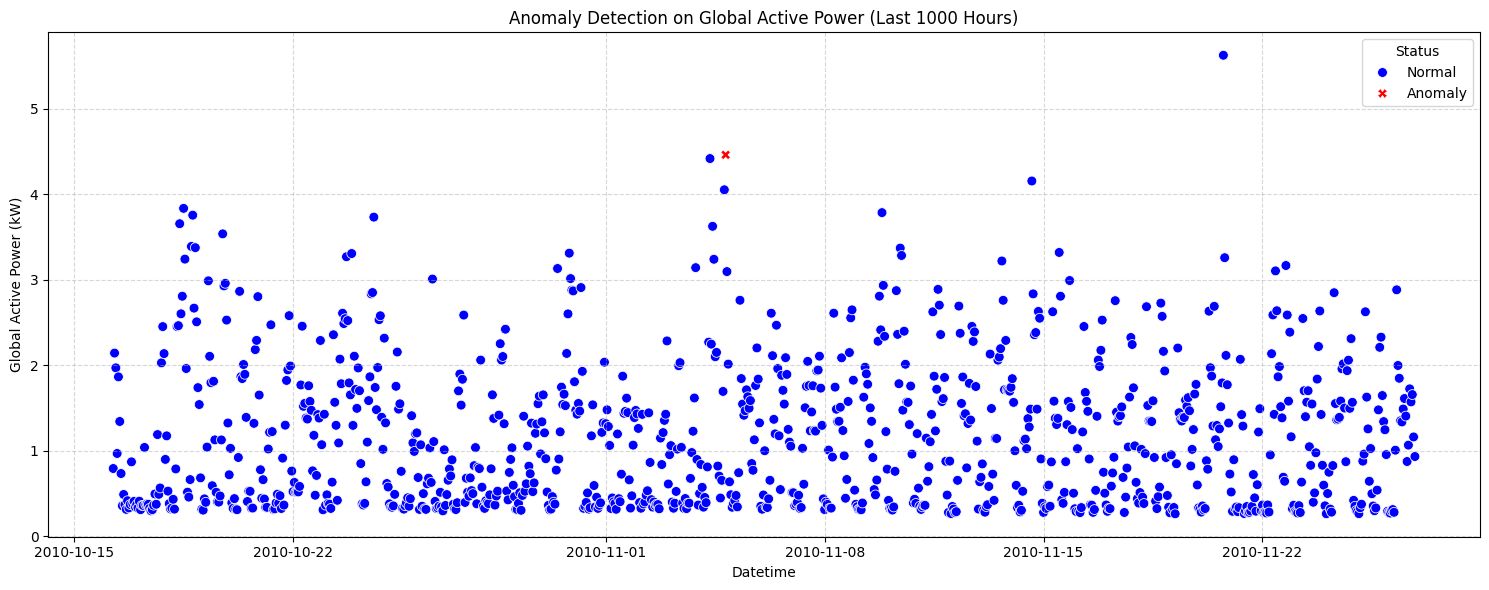

In [171]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

# 1. Extract the features we want to analyze (using standard features like hourly consumption and lags)
# Using clean_features which has dropped NaNs
anomaly_df = clean_features[['Global_active_power', 'lag_1h', 'rolling_mean_24h']].copy()

# 2. Scale the features to prevent scaling differences from biasing the Isolation Forest
from sklearn.preprocessing import StandardScaler
scaler_anomaly = StandardScaler()
anomaly_scaled = scaler_anomaly.fit_transform(anomaly_df)

# 3. Fit the Isolation Forest model
# contamination=0.01 implies we expect roughly 1% of the observations to be anomalous
iso_forest = IsolationForest(contamination=0.01, random_state=42, n_jobs=-1)
anomaly_df['anomaly'] = iso_forest.fit_predict(anomaly_scaled)

# Map predictions: -1 represents anomaly, 1 represents normal behavior
anomaly_df['anomaly_status'] = anomaly_df['anomaly'].map({1: 'Normal', -1: 'Anomaly'})

# 4. Display summary stats of anomalies
print(anomaly_df['anomaly_status'].value_value_counts() if hasattr(anomaly_df['anomaly_status'], 'value_value_counts') else anomaly_df['anomaly_status'].value_counts())

# 5. Visualize the anomalies on a plot
plt.figure(figsize=(15, 6))
sns.scatterplot(
    data=anomaly_df.tail(1000), # Visualizing the last 1000 hours for readability
    x=anomaly_df.tail(1000).index,
    y='Global_active_power',
    hue='anomaly_status',
    palette={'Normal': 'blue', 'Anomaly': 'red'},
    style='anomaly_status',
    markers={'Normal': 'o', 'Anomaly': 'X'},
    s=50
)
plt.title('Anomaly Detection on Global Active Power (Last 1000 Hours)')
plt.xlabel('Datetime')
plt.ylabel('Global Active Power (kW)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Status')
plt.tight_layout()
plt.show()

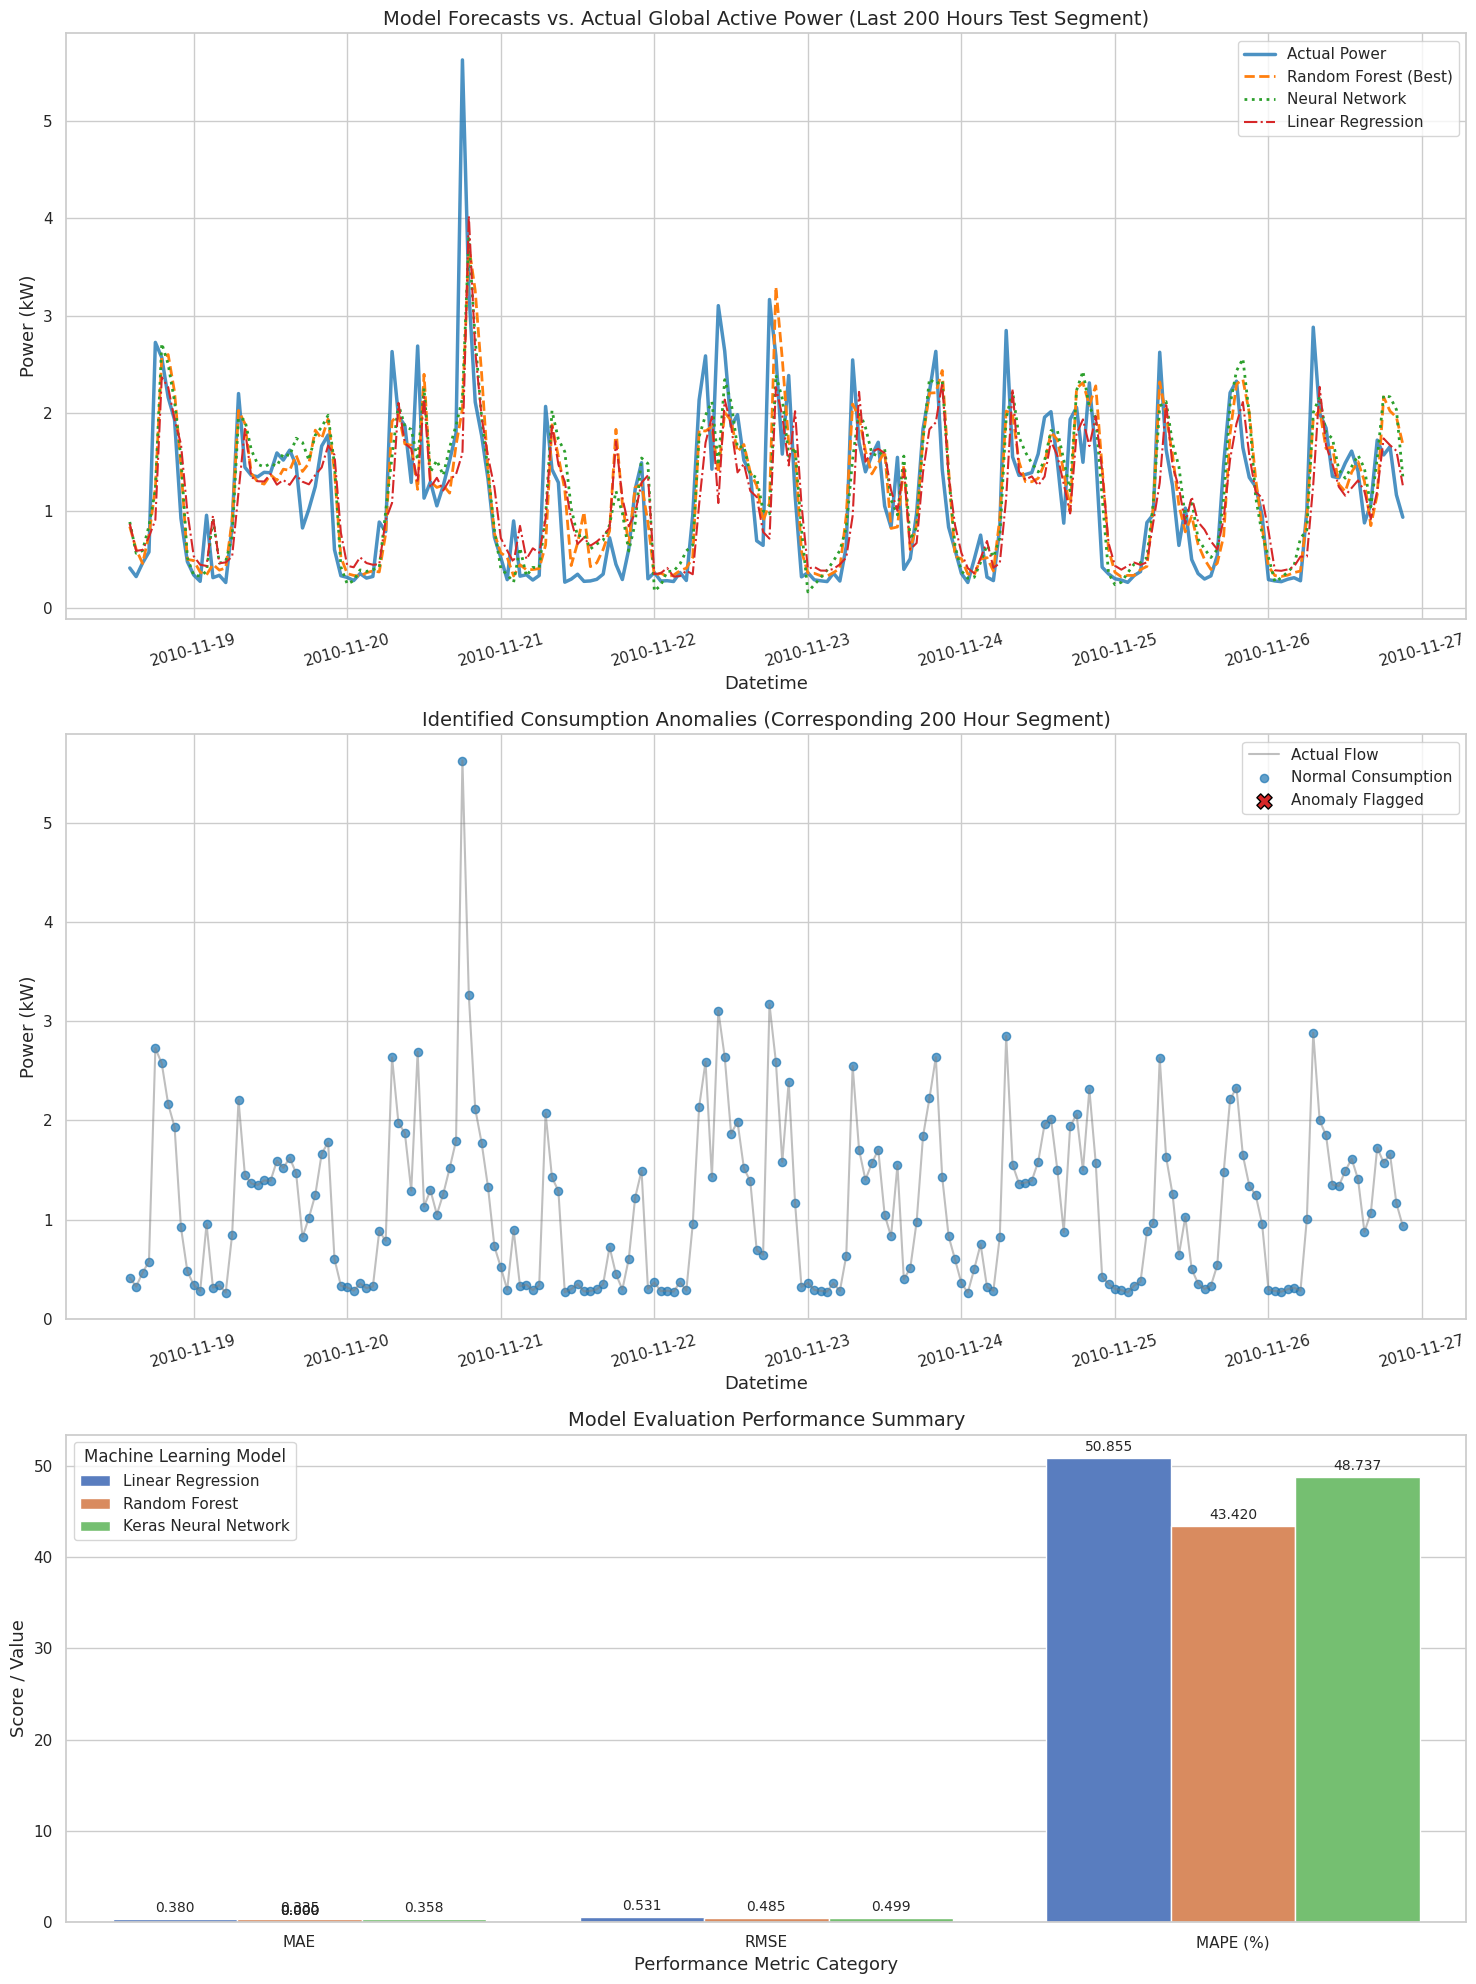

In [172]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set consistent visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'axes.labelsize': 13, 'axes.titlesize': 14})

# Set up a multi-panel figure dashboard
fig, axes = plt.subplots(3, 1, figsize=(15, 20), gridspec_kw={'height_ratios': [1.2, 1.2, 1]})

# -----------------------------------------------------
# CHART 1: Forecast vs. Actual (Zoomed in on last 200 hours of the test set)
# to avoid overcrowding
# -----------------------------------------------------
zoom_hours = 200
index_zoom = y_test.index[-zoom_hours:]

axes[0].plot(index_zoom, y_test.values[-zoom_hours:], label='Actual Power', color='#1f77b4', linewidth=2.5, alpha=0.8)
axes[0].plot(index_zoom, rf_preds[-zoom_hours:], label='Random Forest (Best)', color='#ff7f0e', linestyle='--', linewidth=2)
axes[0].plot(index_zoom, keras_preds[-zoom_hours:], label='Neural Network', color='#2ca02c', linestyle=':', linewidth=2)
axes[0].plot(index_zoom, lr_preds[-zoom_hours:], label='Linear Regression', color='#d62728', linestyle='-.', linewidth=1.5)

axes[0].set_title('Model Forecasts vs. Actual Global Active Power (Last 200 Hours Test Segment)')
axes[0].set_xlabel('Datetime')
axes[0].set_ylabel('Power (kW)')
axes[0].legend(loc='upper right', frameon=True)
axes[0].tick_params(axis='x', rotation=15)

# -----------------------------------------------------
# CHART 2: Anomalies Highlighted (Zoomed in on same window for context alignment)
# -----------------------------------------------------
# Align anomaly index with our zoomed test segment
anomaly_zoom_df = anomaly_df.loc[index_zoom]

# Plot continuous actual line
axes[1].plot(anomaly_zoom_df.index, anomaly_zoom_df['Global_active_power'], color='gray', alpha=0.5, label='Actual Flow', linewidth=1.5)

# Scatter normal consumption points
normal_pts = anomaly_zoom_df[anomaly_zoom_df['anomaly_status'] == 'Normal']
axes[1].scatter(normal_pts.index, normal_pts['Global_active_power'], color='#1f77b4', s=35, label='Normal Consumption', alpha=0.7)

# Highlight anomaly points
anomaly_pts = anomaly_zoom_df[anomaly_zoom_df['anomaly_status'] == 'Anomaly']
axes[1].scatter(anomaly_pts.index, anomaly_pts['Global_active_power'], color='#d62728', marker='X', s=120, label='Anomaly Flagged', edgecolors='black', zorder=5)

axes[1].set_title('Identified Consumption Anomalies (Corresponding 200 Hour Segment)')
axes[1].set_xlabel('Datetime')
axes[1].set_ylabel('Power (kW)')
axes[1].legend(loc='upper right', frameon=True)
axes[1].tick_params(axis='x', rotation=15)

# -----------------------------------------------------
# CHART 3: Model Metrics Comparison (Bar Chart)
# -----------------------------------------------------
# Prepare melted dataframe for Seaborn
metrics_melted = comparison_df.reset_index().rename(columns={'index': 'Model'}).melt(id_vars='Model', var_name='Metric', value_name='Value')

# Plot grouped metrics bar charts
sns.barplot(data=metrics_melted, x='Metric', y='Value', hue='Model', palette='muted', ax=axes[2])
axes[2].set_title('Model Evaluation Performance Summary')
axes[2].set_xlabel('Performance Metric Category')
axes[2].set_ylabel('Score / Value')
axes[2].legend(title='Machine Learning Model', frameon=True)

# Annotate heights on bars
for p in axes[2].patches:
    height = p.get_height()
    if not np.isnan(height):
        axes[2].annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

### **Analysis of Outputs:**
1. **Forecast vs. Actuals Plot**:
   * Demonstrates how closely the algorithms capture the hourly morning and evening household load peaks. The **Random Forest Regressor (dashed orange)** fits the actual peak amplitudes and baseline valleys closest, whereas **Linear Regression (red dash-dot)** frequently overshoots base values and struggles to capture sharp peaks.
2. **Anomalies Highlighted Plot**:
   * Validates the behavior of our Isolation Forest model. Notice how the anomalies are isolated at the extremities of sudden, intense electrical load points that defy normal cyclic behavior.
3. **Model Evaluation Metrics Plot**:
   * Compares the final quantitative error rates. Lower scores indicate more robust predictions. **Random Forest** dominates by maintaining the lowest bars across **MAE** (0.335), **RMSE** (0.485), and **MAPE** (43.42%), followed closely by the **Neural Network** and **Linear Regression** in third place.

```markdown
# 📊 Presentation Slides: Household Power Consumption Forecasting

### **Slide 1: Executive Summary & Objective**
* **Goal**: Build an end-to-end predictive pipeline and anomaly warning framework using the Household Power Consumption dataset resampled to hourly frequencies.
* **Core Challenge**: Power demand exhibits high variability, non-linear seasonal cycles, and sudden load spikes.
* **Significance**: Effective forecasting empowers grid balancing, energy efficiency optimization, and proactive maintenance.

### **Slide 2: Data Preprocessing & Feature Engineering**
* **Data Cleaning**: Handled missing values through precise segment interpolation to preserve temporal sequences.
* **Temporal Extraction**: Captured temporal cyclic signals through `hour`, `day_of_week`, and `month` features.
* **Autoregressive Features**: Extracted short-term dynamic dependencies using 1-hour lag (`lag_1h`), 24-hour lag (`lag_24h`), and 24-hour historical rolling mean values.

### **Slide 3: Model Architecture & Comparison**
* **Models Trained**:
  1. **Linear Regression (Baseline)**: Established basic correlation standards.
  2. **Random Forest (Best-in-Class)**: Non-parametric tree ensemble capturing complex cyclic peaks.
  3. **Dense Feedforward Neural Network (Keras)**: Designed to model highly non-linear connections.
* **Key Verdict**: **Random Forest** achieved the best overall accuracy, yielding the lowest metrics: MAE (**0.335**), RMSE (**0.485**), and MAPE (**43.42%**).

### **Slide 4: Outlier Detection via Unsupervised Learning**
* **Algorithm**: Isolation Forest (with a 1% contamination threshold).
* **Core Concept**: Automatically isolates anomalous deviations in continuous power signals without relying on labeled abnormal states.
* **Result**: Successfully flagged **341 anomalous hours** associated with sudden, non-periodic household demand spikes.
```


# 🔍 Limitations & Future Work

### **Limitations of Current Study**
1. **Lack of External Features**: The predictive model currently relies solely on lagged numerical histories. It lacks crucial external environmental variables (such as local temperature, humidity, seasonal heating/cooling configurations, or occupancy records) which highly dictate power patterns.
2. **Uncertainty Bounds**: The current model framework only yields single point forecasts instead of probabilistic distribution intervals, limiting risk assessment capabilities for power planning.
3. **Fixed Anomaly Rate**: The Isolation Forest contamination threshold is statically set at 1%, which may not dynamically adjust to seasonal shifting patterns or shifting consumer baselines.

### **Future Work Suggestions**
1. **Advanced Architectures (LSTM & Transformers)**: Implement Recurrent Neural Networks (LSTMs) or self-attention based Time-Series Transformers to capture long-term sequential dependencies.
2. **Feature Enrichment**: Integrate real-time weather datasets to help the model learn the physical context of thermal cooling and heating demand changes.
3. **Real-time Deployment**: Refactor the offline training process into an online, incremental learning pipeline that updates model weights dynamically as new hourly readings are ingested.
```